# 3. BW + PLI (Sec. IV-A, Figs. 6, 7, 8)

Made by `scripts/02_bw_pli.py`. Eq. (1): PLI filter on IMF1, BW filter on IMF5-8 (+ residue).
LMS uses the tuned settings; NLMS and RLS use MATLAB's defaults. "LMS, no EMD" is the same
two LMS filters on the whole signal.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # project root, so `src` can be imported

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import FIGURES_DIR, RESULTS_DIR

pd.set_option("display.precision", 2)

In [2]:
d = pd.read_csv(RESULTS_DIR / "bw_pli.csv")
d.groupby(["ecg", "SNRin_dB", "method"]).SNRimp_dB.mean().unstack()

method         EMD+LMS  EMD+NLMS  EMD+RLS  LMS, no EMD
ecg  SNRin_dB                                         
norm -5          18.47      9.22    24.02        18.50
      0          17.27      4.63    21.50        17.10
      5          15.13     -0.30    17.65        14.59
      7          13.56     -2.25    15.63        13.26
      10         11.50     -5.09    12.51        10.96
raw  -5          20.33     11.11    24.79        15.55
      0          17.90      6.57    22.22        15.24
      5          14.15      1.73    19.39        14.42
      7          12.15     -0.26    17.02        13.84
      10          9.52     -3.10    13.87        12.60

## Fig. 8: SNR output at SNRin = 10 dB, ours vs the paper

In [3]:
from src.config import FIG8_RECORDS, PAPER_FIG8

table = d[(d.ecg == "raw") & (d.SNRin_dB == 10)].pivot(index="record", columns="method", values="SNRout_dB")
for name, values in PAPER_FIG8.items():
    table[name] = pd.Series(values, index=FIG8_RECORDS)
table

method,EMD+LMS,EMD+NLMS,EMD+RLS,"LMS, no EMD",Proposed LMS+EMD (paper),Article [28],Article [21],Article [22]
record,,,,,,,,
119,23.99,8.11,30.23,22.55,24.6,17.9,16.5,13.9
202,16.82,4.86,19.96,23.09,22.6,23.0,20.4,18.9
213,22.13,9.46,24.71,23.69,25.0,20.0,17.9,15.9
217,18.98,7.28,24.73,22.78,29.2,25.9,24.0,22.9
234,15.66,4.80,19.73,20.89,23.9,20.4,18.9,18.5


## Figures (raw ECG)

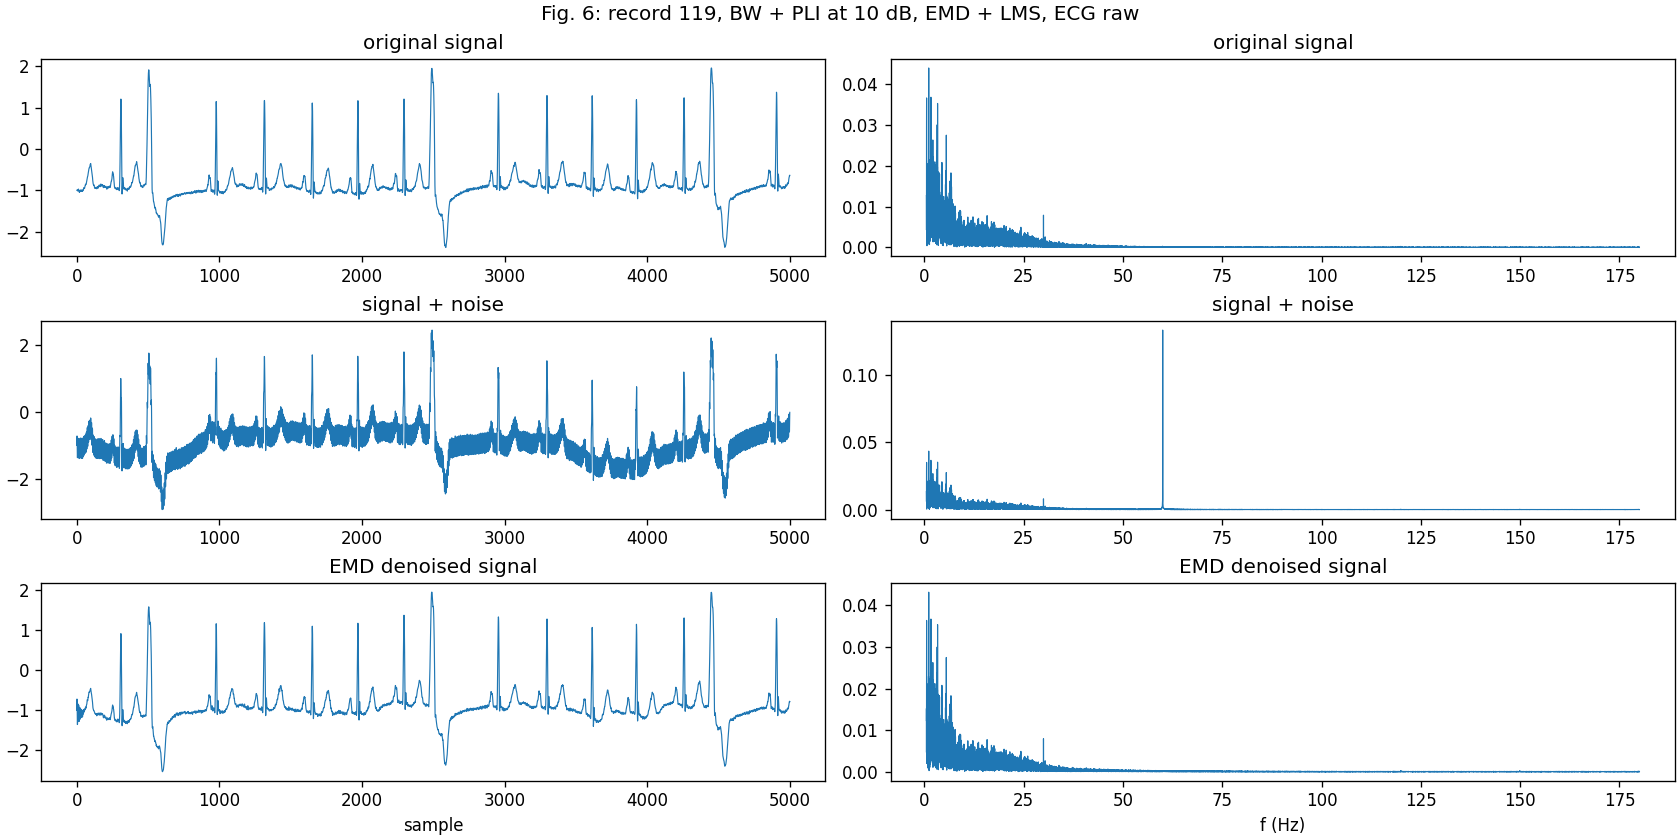

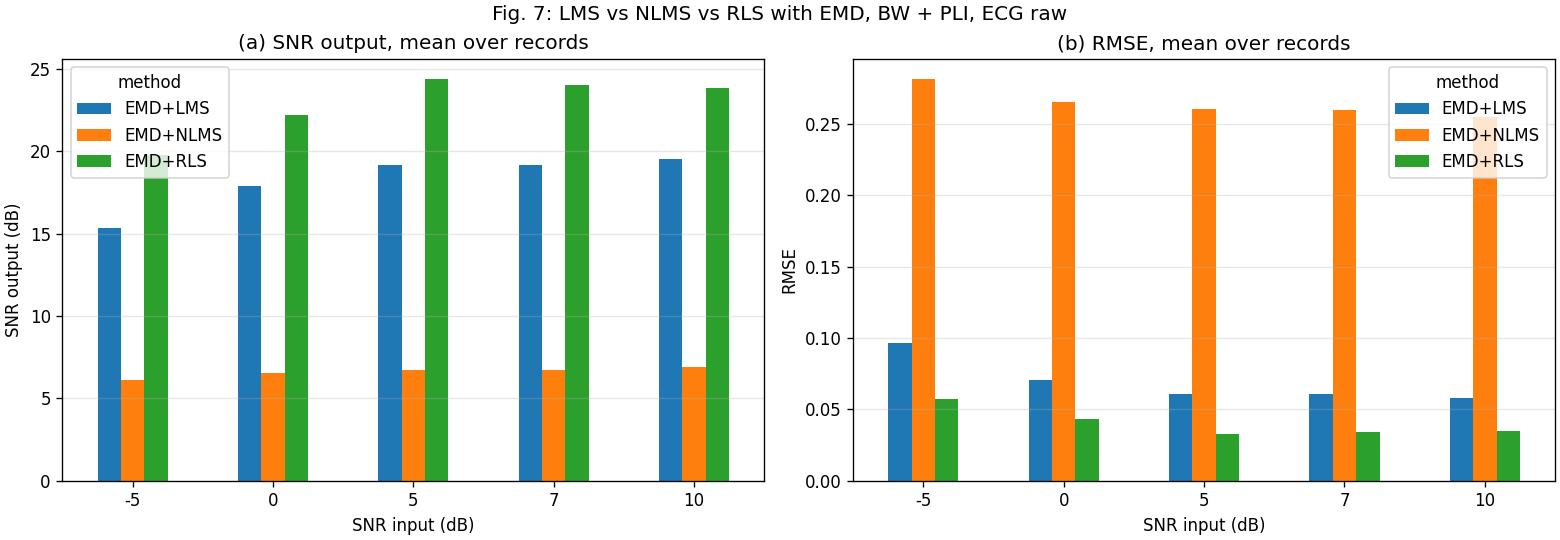

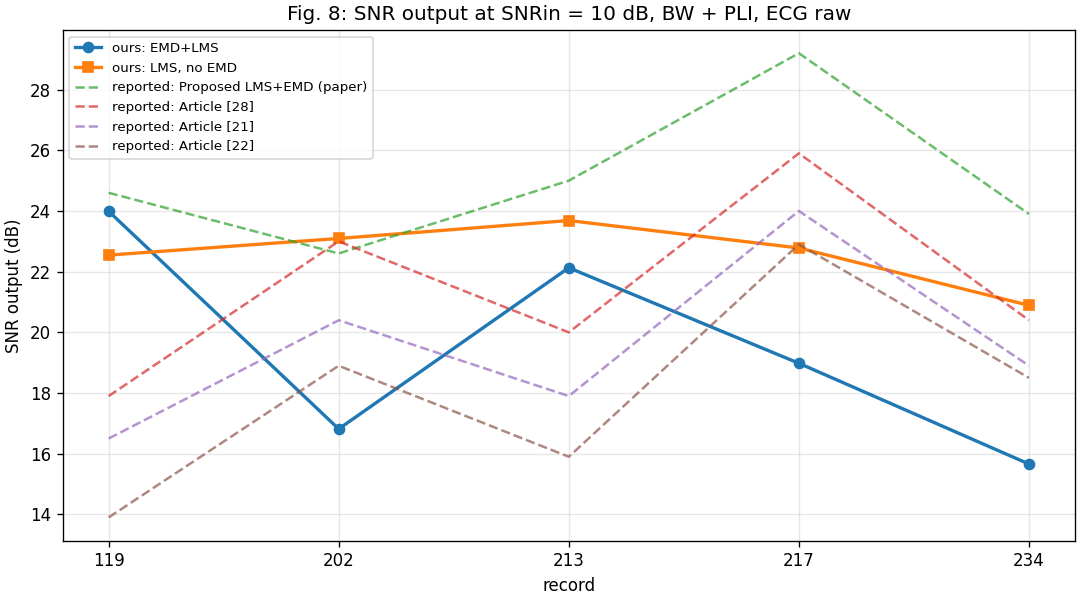

In [4]:
display(Image(FIGURES_DIR / "fig6_raw.png"))
display(Image(FIGURES_DIR / "fig7_raw.png"))
display(Image(FIGURES_DIR / "fig8_raw.png"))

## Figures (normalized ECG)

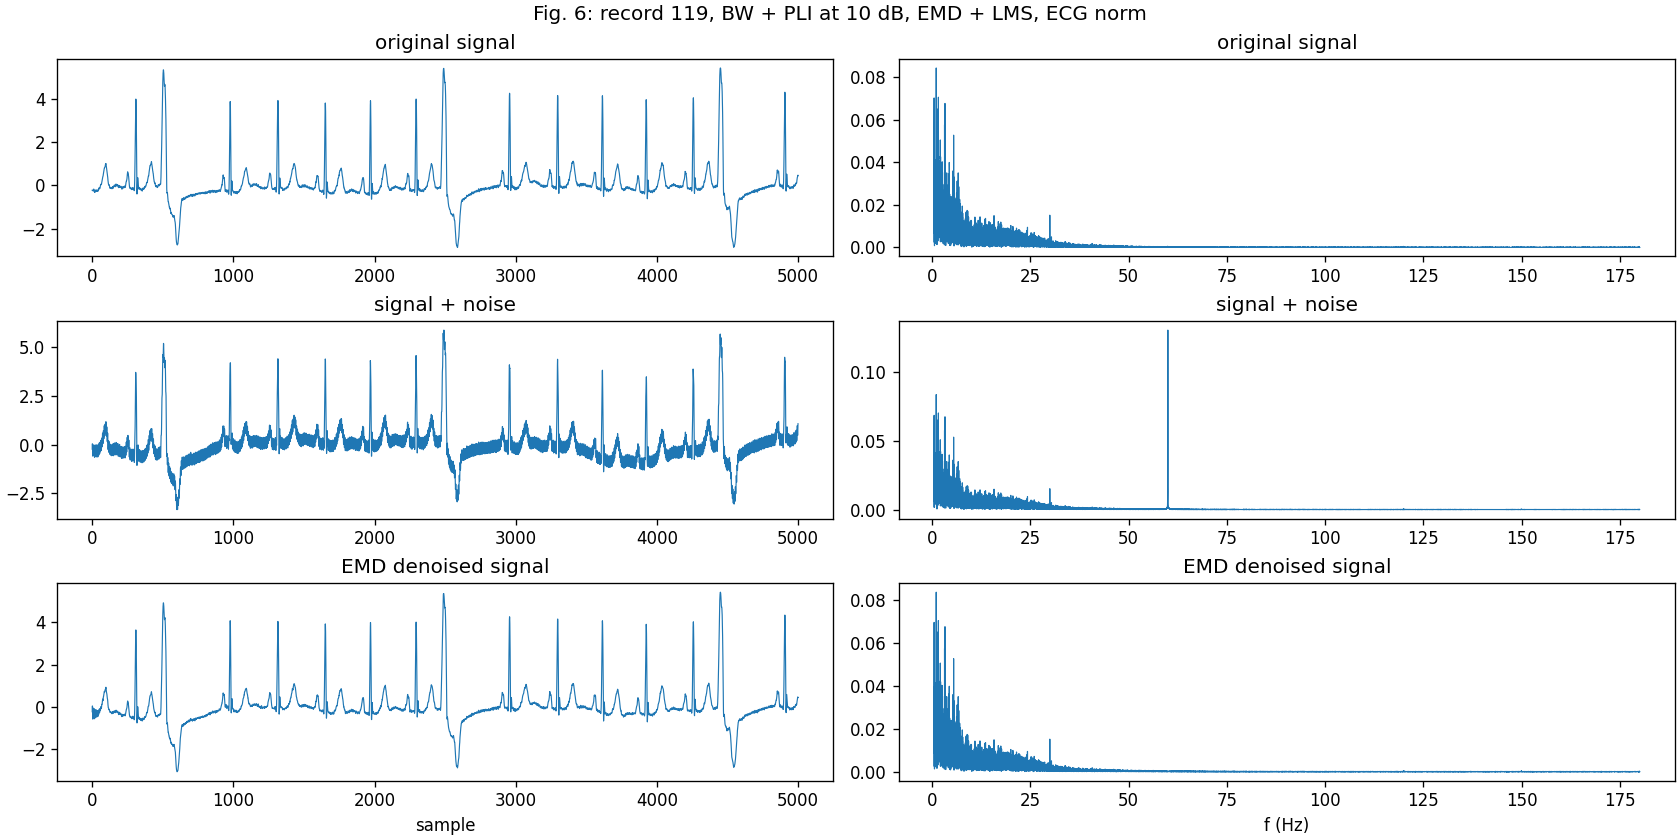

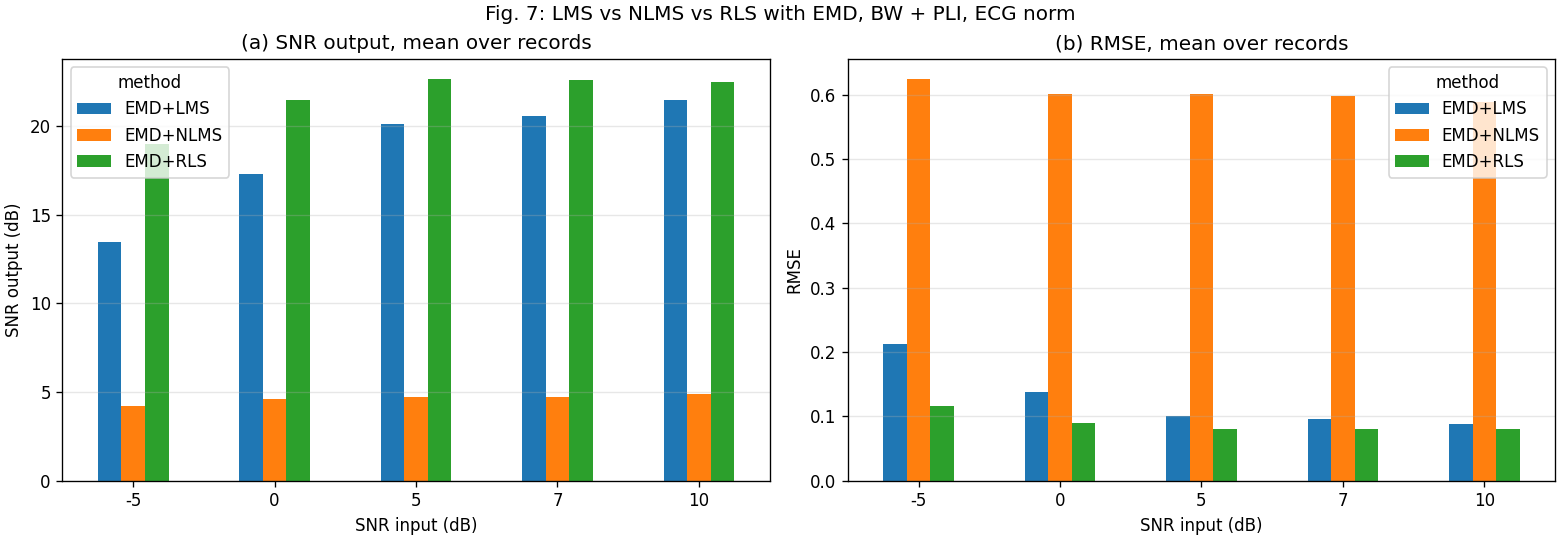

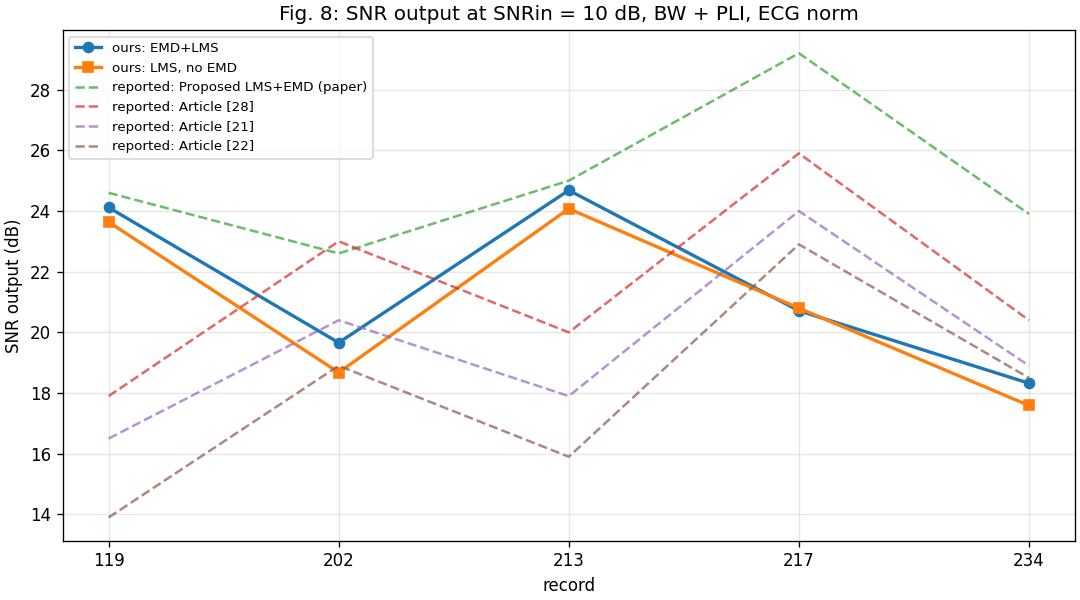

In [5]:
display(Image(FIGURES_DIR / "fig6_norm.png"))
display(Image(FIGURES_DIR / "fig7_norm.png"))
display(Image(FIGURES_DIR / "fig8_norm.png"))